In [21]:
import pandas as pd
from pytrends.request import TrendReq

In [22]:
pytrends = TrendReq(
    hl='en-US',
    tz=360,              
)

In [23]:
kw_list = ["AI Stocks"]

timeframe = "2015-04-01 2025-12-31"
geo = "US"

In [24]:
pytrends.build_payload(
    kw_list=kw_list,
    cat=0,
    timeframe=timeframe,
    geo=geo,
    gprop=""
)

In [25]:
monthly_svi = pytrends.interest_over_time()

monthly_svi = monthly_svi.drop(columns=["isPartial"])

monthly_svi.head()

,AI Stocks
date,
2015-04-01,0
2015-05-01,0
2015-06-01,0
2015-07-01,0
2015-08-01,0


In [26]:
monthly_svi = monthly_svi.reset_index()
monthly_svi.rename(columns={"date": "Month"}, inplace=True)

monthly_svi.head()

,Month,AI Stocks
0,2015-04-01,0
1,2015-05-01,0
2,2015-06-01,0
3,2015-07-01,0
4,2015-08-01,0


In [27]:
monthly_svi["Month"].diff().value_counts()

Month
31 days    74
30 days    44
28 days     7
29 days     3
Name: count, dtype: int64

In [28]:
monthly_svi.tail()

,Month,AI Stocks
124,2025-08-01,100
125,2025-09-01,79
126,2025-10-01,74
127,2025-11-01,74
128,2025-12-01,69


In [29]:
monthly_svi["Month"] = pd.to_datetime(monthly_svi["Month"])

monthly_svi.head()

,Month,AI Stocks
0,2015-04-01,0
1,2015-05-01,0
2,2015-06-01,0
3,2015-07-01,0
4,2015-08-01,0


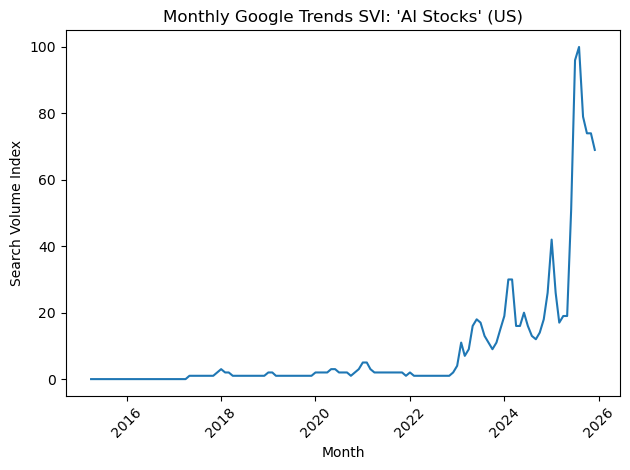

In [30]:
import matplotlib.pyplot as plt

# Make sure data is sorted
monthly_svi = monthly_svi.sort_values("Month")

plt.figure()
plt.plot(monthly_svi["Month"], monthly_svi["AI Stocks"])
plt.title("Monthly Google Trends SVI: 'AI Stocks' (US)")
plt.xlabel("Month")
plt.ylabel("Search Volume Index")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [31]:
import numpy as np

# Ensure sorted
monthly_svi = monthly_svi.sort_values("Month").reset_index(drop=True)

# Avoid log(0) — replace zeros with small positive number 
monthly_svi["SVI_adj"] = monthly_svi["AI Stocks"].replace(0, 0.5)

# Compute rolling 8-month median of past values (t-1 to t-4)
monthly_svi["Median_8"] = (
    monthly_svi["SVI_adj"]
    .rolling(window=8)
    .median()
    .shift(1)
)

# Compute ASVI
monthly_svi["ASVI8"] = np.log(monthly_svi["SVI_adj"]) - np.log(monthly_svi["Median_8"])

monthly_svi.head(12)

,Month,AI Stocks,SVI_adj,Median_8,ASVI8
0,2015-04-01,0,0.5,NaN,NaN
1,2015-05-01,0,0.5,NaN,NaN
2,2015-06-01,0,0.5,NaN,NaN
3,2015-07-01,0,0.5,NaN,NaN
4,2015-08-01,0,0.5,NaN,NaN
5,2015-09-01,0,0.5,NaN,NaN
6,2015-10-01,0,0.5,NaN,NaN
7,2015-11-01,0,0.5,NaN,NaN
8,2015-12-01,0,0.5,0.5,0.0
9,2016-01-01,0,0.5,0.5,0.0


In [32]:
monthly_svi = monthly_svi.dropna(subset=["ASVI8"]).reset_index(drop=True)

In [33]:
monthly_svi.head()

,Month,AI Stocks,SVI_adj,Median_8,ASVI8
0,2015-12-01,0,0.5,0.5,0.0
1,2016-01-01,0,0.5,0.5,0.0
2,2016-02-01,0,0.5,0.5,0.0
3,2016-03-01,0,0.5,0.5,0.0
4,2016-04-01,0,0.5,0.5,0.0


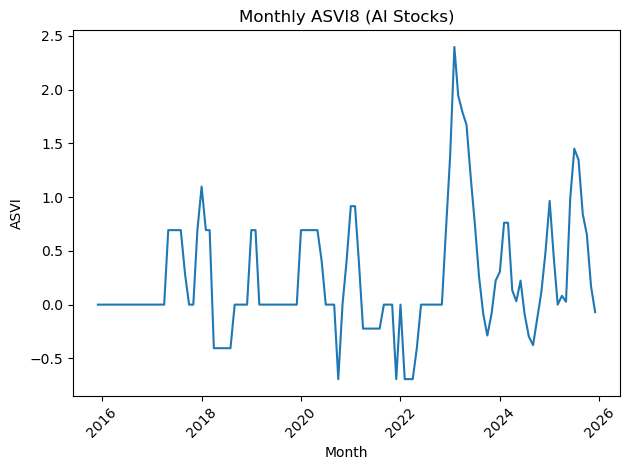

In [34]:
plt.figure()
plt.plot(monthly_svi["Month"], monthly_svi["ASVI8"])
plt.title("Monthly ASVI8 (AI Stocks)")
plt.xlabel("Month")
plt.ylabel("ASVI")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [35]:
monthly_svi.head(12)

,Month,AI Stocks,SVI_adj,Median_8,ASVI8
0,2015-12-01,0,0.5,0.5,0.0
1,2016-01-01,0,0.5,0.5,0.0
2,2016-02-01,0,0.5,0.5,0.0
3,2016-03-01,0,0.5,0.5,0.0
4,2016-04-01,0,0.5,0.5,0.0
5,2016-05-01,0,0.5,0.5,0.0
6,2016-06-01,0,0.5,0.5,0.0
7,2016-07-01,0,0.5,0.5,0.0
8,2016-08-01,0,0.5,0.5,0.0
9,2016-09-01,0,0.5,0.5,0.0


In [36]:
monthly_export = monthly_svi[["Month", "ASVI8"]].copy()

monthly_export = monthly_export.rename(columns={
    "Month": "date"
})



In [37]:
monthly_export["date"] = (
    monthly_export["date"]
        .dt.to_period("M")
        .dt.to_timestamp("M")
)

In [38]:
monthly_export.head()

,date,ASVI8
0,2015-12-31,0.0
1,2016-01-31,0.0
2,2016-02-29,0.0
3,2016-03-31,0.0
4,2016-04-30,0.0


In [39]:
monthly_export.tail()

,date,ASVI8
116,2025-08-31,1.347074
117,2025-09-30,0.843087
118,2025-10-31,0.653407
119,2025-11-30,0.168899
120,2025-12-31,-0.069959


In [40]:
monthly_export.to_csv("AIStocks_ASVI8_Monthly.csv", index=False)